# Day 49 — Build a neural network with PyTorch

You will create two curved classes, build a **2 → 16 → 16 → 1** classifier, train it with minibatches, evaluate on held-out data, and plot the learned decision boundary. The training loop makes Day 48's forward pass, loss, backpropagation, and gradient descent visible.

**Environment:** Google Colab normally includes PyTorch. In a local Python environment, install PyTorch using the instructions at https://pytorch.org/get-started/locally/ before running this notebook. All cells use CPU and need no network dataset.

In [85]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

np.random.seed(19)
torch.manual_seed(7)
print('PyTorch', torch.__version__)

PyTorch 2.6.0


## 1. Create a visible problem

Class 0 follows an upper half circle. Class 1 follows a shifted lower half circle. Noise keeps the problem realistic. The data are created here, so nothing is downloaded.

In [86]:
rng = np.random.default_rng(19)
n_per_class = 240
t0 = rng.uniform(0, np.pi, n_per_class)
t1 = rng.uniform(0, np.pi, n_per_class)
class0 = np.column_stack((np.cos(t0), np.sin(t0)))
class1 = np.column_stack((1 - np.cos(t1), 0.5 - np.sin(t1)))
class0 += rng.normal(0, 0.12, class0.shape)
class1 += rng.normal(0, 0.12, class1.shape)
X_raw = np.vstack((class0, class1)).astype(np.float32)
y_raw = np.vstack((np.zeros((n_per_class, 1)), np.ones((n_per_class, 1)))).astype(np.float32)
print(X_raw.shape, y_raw.shape)  # (480, 2), (480, 1)

(480, 2) (480, 1)


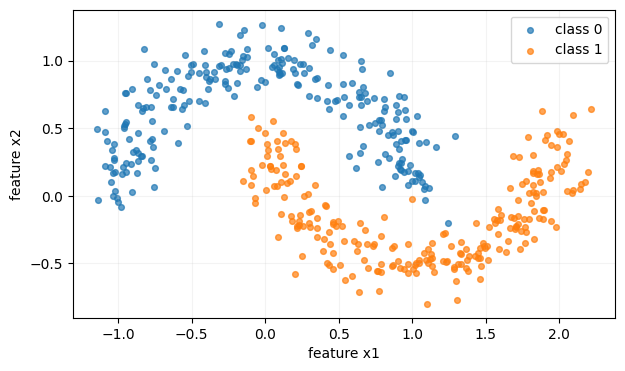

In [87]:
plt.figure(figsize=(7, 4))
plt.scatter(X_raw[y_raw[:, 0] == 0, 0], X_raw[y_raw[:, 0] == 0, 1], s=17, alpha=.7, label='class 0')
plt.scatter(X_raw[y_raw[:, 0] == 1, 0], X_raw[y_raw[:, 0] == 1, 1], s=17, alpha=.7, label='class 1')
plt.xlabel('feature x1'); plt.ylabel('feature x2'); plt.legend(); plt.grid(alpha=.15); plt.show()

## 2. Split and normalize without leakage

Keep **384** examples for training and **96** for validation. Compute the mean and standard deviation using training inputs only. Apply those same values to validation and future inputs. For binary BCE, labels are floating point values and have shape `(batch, 1)`.

In [88]:
perm = rng.permutation(len(X_raw))
train_idx, val_idx = perm[:384], perm[384:]
X_train_raw, X_val_raw = X_raw[train_idx], X_raw[val_idx]
y_train_raw, y_val_raw = y_raw[train_idx], y_raw[val_idx]
train_mean = X_train_raw.mean(axis=0)
train_std = X_train_raw.std(axis=0).clip(min=1e-6)
X_train = torch.tensor((X_train_raw - train_mean) / train_std, dtype=torch.float32)
X_val = torch.tensor((X_val_raw - train_mean) / train_std, dtype=torch.float32)
y_train = torch.tensor(y_train_raw, dtype=torch.float32)
y_val = torch.tensor(y_val_raw, dtype=torch.float32)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)
print(X_train.shape, y_train.shape, X_val.shape, y_val.shape)
assert X_train.shape == (384, 2) and y_train.shape == (384, 1)

torch.Size([384, 2]) torch.Size([384, 1]) torch.Size([96, 2]) torch.Size([96, 1])


In [89]:
xb, yb = next(iter(train_loader))
print('one batch:', xb.shape, yb.shape, xb.dtype, yb.dtype)
assert xb.shape == (32, 2) and yb.shape == (32, 1)

one batch: torch.Size([32, 2]) torch.Size([32, 1]) torch.float32 torch.float32


## 3. Build the layers

`nn.Linear(in_features, out_features)` stores a weight matrix and bias. `nn.Tanh()` supplies the nonlinearity. The last `nn.Linear(16, 1)` returns a **logit**, not a probability. `nn.Sequential` passes each layer's output to the next.

In [90]:
def build_model(width=128):
    return nn.Sequential(
        nn.Linear(2, width), nn.Tanh(),
        nn.Linear(width, width), nn.Tanh(),
        nn.Linear(width, 1),  # raw logits
    )

model = build_model()
print(model)
for name, parameter in model.named_parameters():
    print(name, tuple(parameter.shape))

Sequential(
  (0): Linear(in_features=2, out_features=128, bias=True)
  (1): Tanh()
  (2): Linear(in_features=128, out_features=128, bias=True)
  (3): Tanh()
  (4): Linear(in_features=128, out_features=1, bias=True)
)
0.weight (128, 2)
0.bias (128,)
2.weight (128, 128)
2.bias (128,)
4.weight (1, 128)
4.bias (1,)


For a batch of size $B$: input `(B, 2)` → first hidden `(B, 16)` → second hidden `(B, 16)` → logits `(B, 1)`. The three `Linear` weight matrices have shapes `(16, 2)`, `(16, 16)`, and `(1, 16)`.

In [91]:
with torch.no_grad():
    z1 = model[0](xb)
    a1 = model[1](z1)
    z2 = model[2](a1)
    a2 = model[3](z2)
    logits = model[4](a2)
print('input', xb.shape, 'hidden 1', a1.shape, 'hidden 2', a2.shape, 'logits', logits.shape)
print('first three logits:', logits[:3, 0])

input torch.Size([32, 2]) hidden 1 torch.Size([32, 128]) hidden 2 torch.Size([32, 128]) logits torch.Size([32, 1])
first three logits: tensor([-0.1424,  0.0894,  0.0567])


## 4. Use a stable binary loss

`nn.BCEWithLogitsLoss()` combines sigmoid and binary cross entropy. Pass it raw logits and a target tensor with the **same shape**. For reporting, `torch.sigmoid(logits)` yields probabilities. Applying sigmoid before this loss would apply it twice.

In [92]:
criterion = nn.BCEWithLogitsLoss()
logits = model(xb)
loss = criterion(logits, yb)
probabilities = torch.sigmoid(logits)
print('logits', logits.shape, 'targets', yb.shape, 'loss', loss.item())
print('first probability', probabilities[0, 0].item())
assert logits.shape == yb.shape and loss.ndim == 0

logits torch.Size([32, 1]) targets torch.Size([32, 1]) loss 0.787081778049469
first probability 0.4644658863544464


## 5. Inspect one actual parameter update

`zero_grad()` clears accumulated gradients. `backward()` computes them by the chain rule. `step()` changes parameters. The three operations must be associated with the **same minibatch loss**.

In [93]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.15)
before = model[0].weight.detach().clone()
optimizer.zero_grad()
logits = model(xb)
loss = criterion(logits, yb)
loss.backward()
print('weight shape', tuple(model[0].weight.shape), 'gradient shape', tuple(model[0].weight.grad.shape))
print('one gradient', model[0].weight.grad[0, 0].item())
optimizer.step()
after = model[0].weight.detach().clone()
print('weight changed:', not torch.equal(before, after))
assert not torch.equal(before, after)

weight shape (128, 2) gradient shape (128, 2)
one gradient 0.0010666471207514405
weight changed: True


The operation above is a single learning step. We now start a **fresh model** so the complete training run has a clean, reproducible beginning.

## 6. Train and record both curves

There are 12 batches per epoch because $384 / 32 = 12$. For each batch: reset gradients, forward, loss, backward, update. Validation runs with `model.eval()` and `torch.no_grad()`; it does not update parameters. We weight each batch loss by its number of examples when averaging.

In [ ]:
torch.manual_seed(7)
model = build_model()
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.15)
train_history, val_history = [], []
for epoch in range(300):
    model.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        logits = model(xb)
        batch_loss = criterion(logits, yb)
        batch_loss.backward()
        optimizer.step()
        total_loss += batch_loss.item() * len(xb)
    train_history.append(total_loss / len(X_train))

    model.eval()
    with torch.no_grad():
        val_history.append(criterion(model(X_val), y_val).item())

print('first / last train loss:', train_history[0], train_history[-1])
print('first / last validation loss:', val_history[0], val_history[-1])

first / last train loss: 0.38298332194487256 0.0005786656559697197
first / last validation loss: 0.3411339819431305 0.07496470212936401


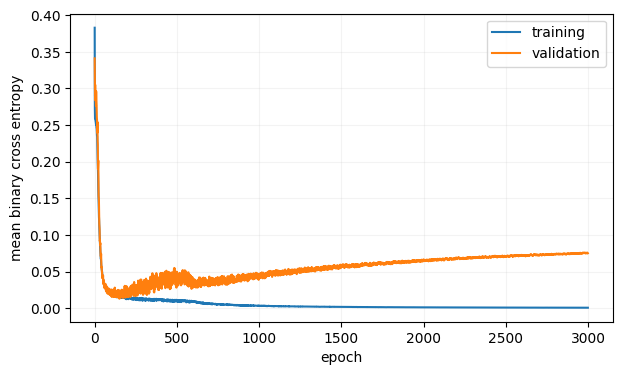

In [95]:
plt.figure(figsize=(7, 4))
plt.plot(train_history, label='training')
plt.plot(val_history, label='validation')
plt.xlabel('epoch'); plt.ylabel('mean binary cross entropy')
plt.legend(); plt.grid(alpha=.15); plt.show()

## 7. Evaluate probabilities and labels

Threshold the **probability** at 0.5 (equivalent to thresholding the logit at 0). Accuracy is the fraction of labels predicted correctly. Also inspect the validation loss because accuracy loses confidence information.

In [96]:
model.eval()
with torch.no_grad():
    val_logits = model(X_val)
    val_probs = torch.sigmoid(val_logits)
    val_pred = (val_probs >= .5).float()
    accuracy = (val_pred == y_val).float().mean().item()
print(f'validation accuracy: {accuracy:.3f}')
print(f'validation BCE: {val_history[-1]:.3f}')
print('first five probabilities:', val_probs[:5, 0].numpy().round(3))

validation accuracy: 0.979
validation BCE: 0.075
first five probabilities: [1. 0. 0. 0. 1.]


## 8. Draw the decision boundary

Create a dense grid in the **original feature coordinates**, normalize grid points with the training mean and standard deviation, run the model without gradients, then draw the contour where $p=0.5$.

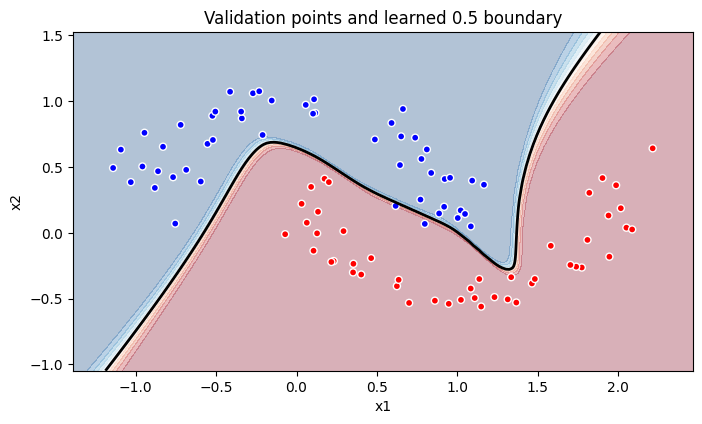

In [97]:
gx, gy = np.meshgrid(
    np.linspace(X_raw[:, 0].min()-.25, X_raw[:, 0].max()+.25, 180),
    np.linspace(X_raw[:, 1].min()-.25, X_raw[:, 1].max()+.25, 150),
)
grid_raw = np.column_stack([gx.ravel(), gy.ravel()]).astype(np.float32)
grid_scaled = torch.tensor((grid_raw-train_mean)/train_std, dtype=torch.float32)
with torch.no_grad():
    surface = torch.sigmoid(model(grid_scaled)).reshape(gx.shape).numpy()
plt.figure(figsize=(8, 4.4))
plt.contourf(gx, gy, surface, levels=np.linspace(0, 1, 12), cmap='RdBu_r', alpha=.32)
plt.contour(gx, gy, surface, levels=[.5], colors='black', linewidths=2)
plt.scatter(X_val_raw[:, 0], X_val_raw[:, 1], c=y_val_raw[:, 0], cmap='bwr', edgecolors='white', s=26)
plt.title('Validation points and learned 0.5 boundary'); plt.xlabel('x1'); plt.ylabel('x2'); plt.show()

## 9. Save and reload only the weights

The in-memory buffer avoids leaving an extra file in the course folder. To persist a model yourself, pass a filename to `torch.save(model.state_dict(), filename)` and load it into a newly constructed `build_model()` with the same width.

In [ ]:
import io
buffer = io.BytesIO()
torch.save(model.state_dict(), buffer)
buffer.seek(0)
reloaded = build_model()
reloaded.load_state_dict(torch.load(buffer, map_location='cpu', weights_only=True))
reloaded.eval()
with torch.no_grad():
    assert torch.allclose(model(X_val), reloaded(X_val))
print('Reloaded model gives the same logits.')

Reloaded model gives the same logits.


## 10. Keras / TensorFlow translation (optional)

The following code defines the same shapes and logits-based loss. `fit()` runs the standard minibatch loop. The PyTorch notebook remains the main executable lesson.

```python
import tensorflow as tf
keras_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    tf.keras.layers.Dense(16, activation='tanh'),
    tf.keras.layers.Dense(16, activation='tanh'),
    tf.keras.layers.Dense(1),  # logits
])
keras_model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.15),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[tf.keras.metrics.BinaryAccuracy(threshold=0.0)],
)
history = keras_model.fit(X_train.numpy(), y_train.numpy(),
    validation_data=(X_val.numpy(), y_val.numpy()),
    epochs=150, batch_size=32, verbose=0)
```

The Keras and PyTorch models will not necessarily produce identical curves because initialization and batch ordering differ.

## Summary and references

- `nn.Linear` holds weights and biases. `Tanh` adds nonlinear transformations.
- `model(x)` is forward propagation; `BCEWithLogitsLoss` measures binary error from logits.
- `loss.backward()` produces gradients; `optimizer.step()` updates weights; `zero_grad()` prevents unwanted accumulation.
- Validation uses `eval()` and `no_grad()`; new data uses the training normalization.

Official docs: [PyTorch building a network](https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html), [optimization loop](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html), [BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html), [saving/loading](https://docs.pytorch.org/tutorials/beginner/basics/saveloadrun_tutorial.html), and [Keras Sequential](https://www.tensorflow.org/guide/keras/sequential_model).